In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score

In [4]:

train = pd.read_csv('../data/processed/train.csv')
val = pd.read_csv('../data/processed/val.csv')

print(train.shape, val.shape)
print(train['text_clean'].isna().sum(), val['text_clean'].isna().sum())
print(train['label'].value_counts(normalize=True).round(3))

X_train, y_train = train['text_clean'], train['label']
X_val, y_val = val['text_clean'], val['label']

(9811, 5) (2103, 5)
0 0
label
0    0.642
1    0.204
2    0.154
Name: proportion, dtype: float64


In [7]:
vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)

X_train_vec = vectorizer.fit_transform(X_train)   # learn vocabulary from train, then transform
X_val_vec = vectorizer.transform(X_val)           # only transform, using train's vocabulary

print(X_train_vec.shape, X_val_vec.shape)

(9811, 20522) (2103, 20522)


# Logistic regression - base model

In [8]:
model = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
model.fit(X_train_vec, y_train)

val_pred = model.predict(X_val_vec)
print('macro-F1:', round(f1_score(y_val, val_pred, average='macro'), 3))
print(classification_report(y_val, val_pred, target_names=['negative', 'neutral', 'positive']))

macro-F1: 0.74
              precision    recall  f1-score   support

    negative       0.89      0.85      0.87      1351
     neutral       0.59      0.68      0.63       429
    positive       0.72      0.72      0.72       323

    accuracy                           0.79      2103
   macro avg       0.73      0.75      0.74      2103
weighted avg       0.80      0.79      0.80      2103



In [9]:
labels = ['negative', 'neutral', 'positive']
cm = pd.crosstab(
    y_val.map(dict(enumerate(labels))),
    pd.Series(val_pred, index=y_val.index).map(dict(enumerate(labels))),
    rownames=['actual'], colnames=['predicted']
)
print(cm)

predicted  negative  neutral  positive
actual                                
negative       1147      157        47
neutral          94      291        44
positive         48       43       232


# Logistic reg - without balanced weight

In [ ]:
m2 = LogisticRegression(max_iter=1000, random_state=42)   # no class_weight
m2.fit(X_train_vec, y_train)
print(classification_report(y_val, m2.predict(X_val_vec), target_names=['negative', 'neutral', 'positive']))

              precision    recall  f1-score   support

    negative       0.81      0.97      0.88      1351
     neutral       0.76      0.47      0.58       429
    positive       0.84      0.57      0.68       323

    accuracy                           0.80      2103
   macro avg       0.80      0.67      0.71      2103
weighted avg       0.80      0.80      0.79      2103



# m1 vs m2

m1 is the model from above (class_weight='balanced'). m2 is the same model with no class weights. Nothing else changed, same features and same split, so any difference comes from the weighting alone.

| | m1 (balanced) | m2 (no weights) |
|---|---|---|
| macro-F1 | 0.74 | 0.71 |
| accuracy | 0.79 | 0.80 |
| neutral recall | 0.68 | 0.47 |
| positive recall | 0.72 | 0.57 |
| negative recall | 0.85 | 0.97 |

Without weights the model leans toward negative, because that is 64% of the training data. It finds 97% of negative tweets but misses more than half of the neutral ones. With balanced weights, neutral and positive recall go up a lot. The cost is lower precision on those two classes, since the model now sometimes calls a negative tweet neutral.

Accuracy is actually a little higher without the weights, which is why I'm not using accuracy to pick a model. It rewards the model that just plays the majority class.

Negative F1 is about the same in both (0.87 and 0.88). So negative isn't doing well only because of imbalance, those tweets have very clear words (delayed, worst, hold, cancelled).

Keeping class_weight='balanced' for everything from here on.

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

for C in [0.1, 0.3, 1, 3, 10]:
    m = LogisticRegression(C=C, max_iter=1000, class_weight='balanced', random_state=42)
    m.fit(X_train_vec, y_train)
    score = f1_score(y_val, m.predict(X_val_vec), average='macro')
    print(C, round(score, 3))

0.1 0.721
0.3 0.728
1 0.74
3 0.743
10 0.74


## Tuning C

Tried C = 0.1, 0.3, 1, 3, 10 with class weights on, scoring macro-F1 on val.

| C | macro-F1 |
|---|---|
| 0.1 | 0.721 |
| 0.3 | 0.728 |
| 1 | 0.740 |
| 3 | 0.743 |
| 10 | 0.740 |

Very small C holds the model back and costs about two points. From C=1 upwards it is flat, and the 0.003 gap between 1 and 3 is well within noise for a 2,103 tweet val set. So I'm keeping the default C=1, the simpler option. The takeaway is that this model isn't sensitive to C, and any real improvement has to come from somewhere else.

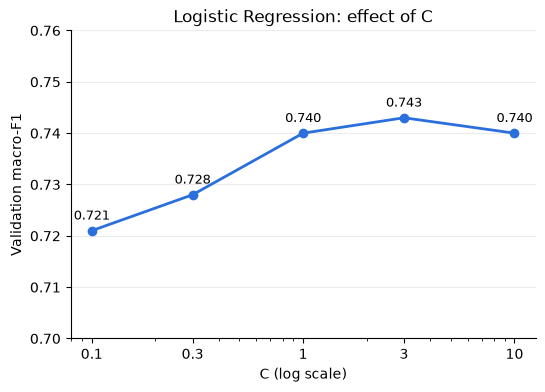

In [22]:
C_vals = [0.1, 0.3, 1, 3, 10]
lr_scores = [0.721, 0.728, 0.740, 0.743, 0.740]

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(C_vals, lr_scores, marker='o', color=BLUE, linewidth=2)
ax.set_xscale('log')
ax.set_xticks(C_vals)
ax.set_xticklabels([str(c) for c in C_vals])
for c, s in zip(C_vals, lr_scores):
    ax.annotate(f'{s:.3f}', (c, s), textcoords='offset points',
                xytext=(0, 8), ha='center', fontsize=9)
ax.set_xlabel('C (log scale)')
ax.set_ylabel('Validation macro-F1')
ax.set_title('Logistic Regression: effect of C')
ax.set_ylim(0.70, 0.76)
ax.grid(axis='y', alpha=0.25)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

# SVM

In [19]:
from sklearn.svm import LinearSVC

for C in [0.03, 0.1, 0.3, 1]:
    s = LinearSVC(C=C, class_weight='balanced', max_iter=5000, random_state=42)
    s.fit(X_train_vec, y_train)
    score = f1_score(y_val, s.predict(X_val_vec), average='macro')
    print(C, round(score, 3))

0.03 0.707
0.1 0.752
0.3 0.747
1 0.743


Comparing all models till now


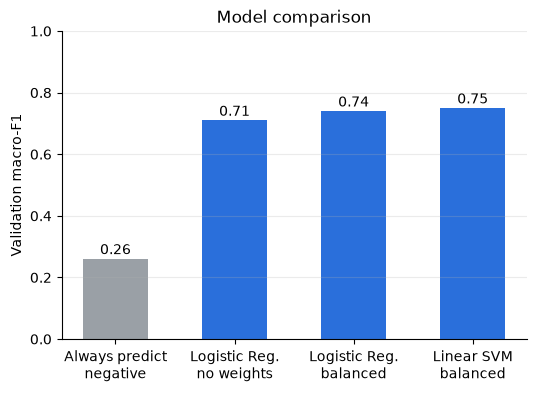

In [ ]:
BLUE = '#2a6fdb'
GRAY = '#9aa0a6'

floor = f1_score(y_val, np.zeros(len(y_val), dtype=int), average='macro')  # always predict negative

results = {
    
    'Always predict\nnegative': floor,
    'Logistic Reg.\nno weights': 0.71,
    'Logistic Reg.\nbalanced': 0.74,
    'Linear SVM\nbalanced': 0.75,

}

fig, ax = plt.subplots(figsize=(6, 4))
colors = [GRAY] + [BLUE] * (len(results) - 1)
bars = ax.bar(list(results.keys()), list(results.values()), color=colors, width=0.55)
for b, v in zip(bars, results.values()):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.015, f'{v:.2f}', ha='center', fontsize=10)
ax.set_ylim(0, 1)
ax.set_ylabel('Validation macro-F1')
ax.set_title('Model comparison')
ax.grid(axis='y', alpha=0.25)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

## Linear SVM

Same features and class weights as Logistic Regression. Tried C = 0.03, 0.1, 0.3 and 1.

| C | macro-F1 |
|---|---|
| 0.03 | 0.707 |
| 0.1 | 0.752 |
| 0.3 | 0.747 |
| 1 | 0.743 |

Best SVM is 0.752 at C = 0.1, against 0.743 for Logistic Regression. That is less than one point apart, which is inside the noise of a 2,103 tweet val set, so I'm calling it a tie. I'm keeping Logistic Regression because it gives class probabilities, which I want to show on the website.

In [25]:
from sklearn.pipeline import Pipeline
from pathlib import Path
import joblib

final = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
    ('clf', LogisticRegression(C=3, max_iter=1000, class_weight='balanced', random_state=42)),
])
final.fit(X_train, y_train)

test = pd.read_csv('../data/processed/test.csv')
test_pred = final.predict(test['text_clean'])

print('test macro-F1:', round(f1_score(test['label'], test_pred, average='macro'), 3))
print(classification_report(test['label'], test_pred, target_names=['negative', 'neutral', 'positive']))

Path('../models').mkdir(exist_ok=True)
joblib.dump(final, '../models/baseline_lr.joblib')

test macro-F1: 0.75
              precision    recall  f1-score   support

    negative       0.88      0.87      0.88      1351
     neutral       0.61      0.65      0.63       430
    positive       0.75      0.74      0.74       322

    accuracy                           0.80      2103
   macro avg       0.75      0.75      0.75      2103
weighted avg       0.81      0.80      0.80      2103



['../models/baseline_lr.joblib']

## Final baseline on test

Fitted TF-IDF + Logistic Regression (balanced weights, C = 3) on train only, then scored on the test set once. Test macro-F1 is 0.75 and accuracy is 0.80, very close to the 0.743 on val, so the tuning didn't just fit the val set by luck.

Per class F1: negative 0.88, positive 0.74, neutral 0.63. Neutral is still the weak spot

The pipeline (vectorizer and model together) is saved to models/baseline_lr.joblib so the API can load a single file later.


